# Fig. 7 · L5 过程与相变路径（1200 → 300 K 淬火，15 K ps⁻¹）

**主张**：比较整条温度程序，而不只是终态；容差来自三条独立 AIMD 链之间的涨落，而不是拍定的阈值。

- **a** 四面体 Ge 比例；**b** 四元环密度；**c** 平均配位数——均为沿淬火路径的变化，灰带 = 参考 3σ 带。
- **d** 路径终点误差（全部观测量平均）；**e** 首次偏离出参考带的位置（进度 0–1，越晚越好）；**f** 升温程序（300 → 1200 K）中的四面体 Ge 比例。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig7_L5"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 2
LETTERS = "abcdef"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
def model_rows(ax, show_labels):
    """Shared y axis for the nine-model summary panels: universal on top, specialised below."""
    y = {k: i for i, k in enumerate(SHOWCASE)}
    ax.set_ylim(len(SHOWCASE) - 0.4, -0.6)
    ax.set_yticks(range(len(SHOWCASE)))
    ax.set_yticklabels([lab(k) for k in SHOWCASE] if show_labels else [])
    ax.axhline(len(UNIVERSAL) - 0.5, color="#BBBBBB", lw=0.4, ls=(0, (2, 2)))
    ax.tick_params(axis="y", length=0)
    return y

def contaminated(model):
    from mlipeval.ranking import contaminated_metric_ids
    return set(contaminated_metric_ids([model]))

In [5]:
Q = {k: npz(k, "l5_canon_quench.npz") for k in SHOWCASE}
HT = {k: npz(k, "l5_canon_heating.npz") for k in SHOWCASE}
RA = ranking(SHOWCASE, clean=False)
ROW = {r.indicator.key: r for r in RA.rows}

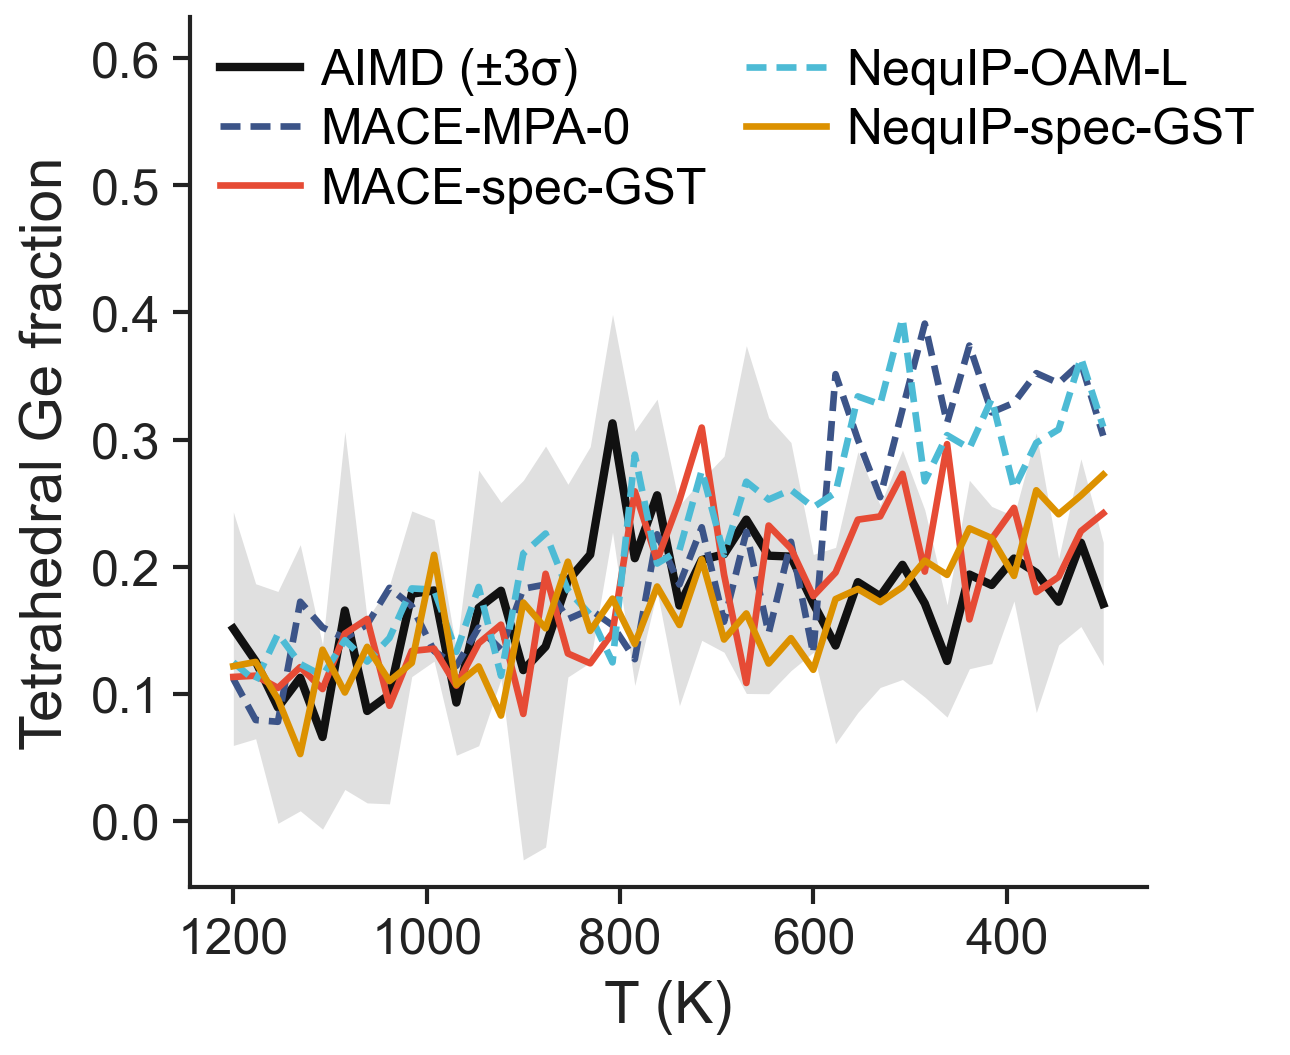

In [6]:
# ---------------- 本面板配色 ----------------
Ca_REF, Ca_BAND = "#111111", "#E0E0E0"
# --------------------------------------------
def path_panel(fig, spec, Z, obs, ylabel, legend, invert=True):
    ax = fig.add_subplot(spec)
    z0 = Z["mace_mpa0"]
    T = z0["ref_nominal_temperature_K"]; y = z0[f"ref_{obs}"]; b = z0[f"band_{obs}"]
    ax.fill_between(T, y - b, y + b, color=Ca_BAND, lw=0)
    ax.plot(T, y, color=Ca_REF, lw=1.0, label="AIMD (±3σ)")
    for k in FOCUS:
        z = Z[k]; ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.plot(z["model_nominal_temperature_K"], z[f"model_{obs}"], color=col(k), lw=0.8, ls=ls, label=lab(k))
    if invert: ax.invert_xaxis()
    ax.set_xlabel("T (K)"); ax.set_ylabel(ylabel)
    if legend:
        ax.legend(loc="upper left", ncol=2, columnspacing=0.8)
        lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.45 * (hi - lo))
    return ax
def draw_a(fig, spec):
    return path_panel(fig, spec, Q, "tetrahedral_fraction", "Tetrahedral Ge fraction", True)
panel_run("a", draw_a)

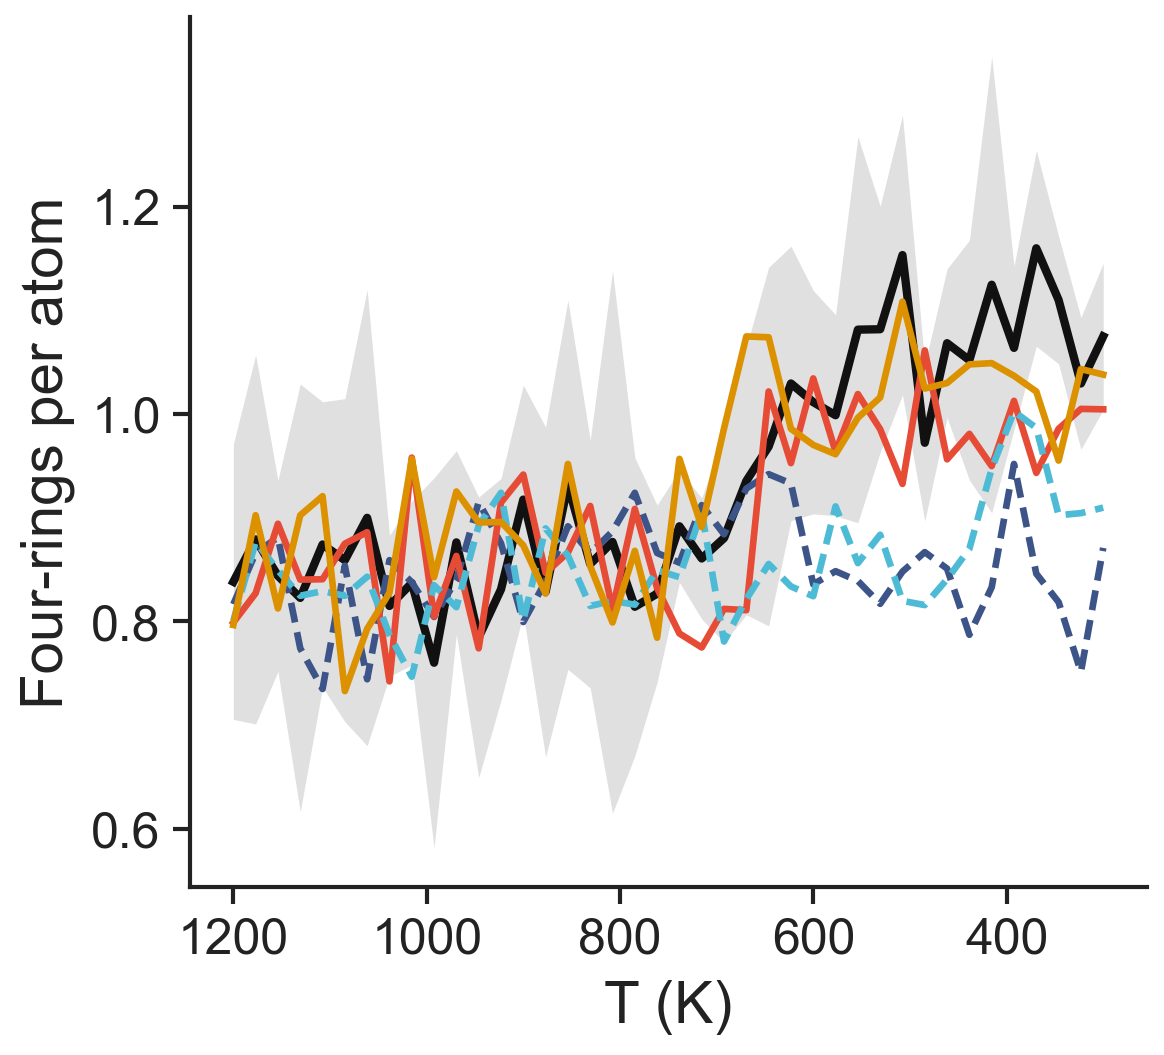

In [7]:
def draw_b(fig, spec):
    return path_panel(fig, spec, Q, "four_rings_per_atom", "Four-rings per atom", False)
panel_run("b", draw_b)

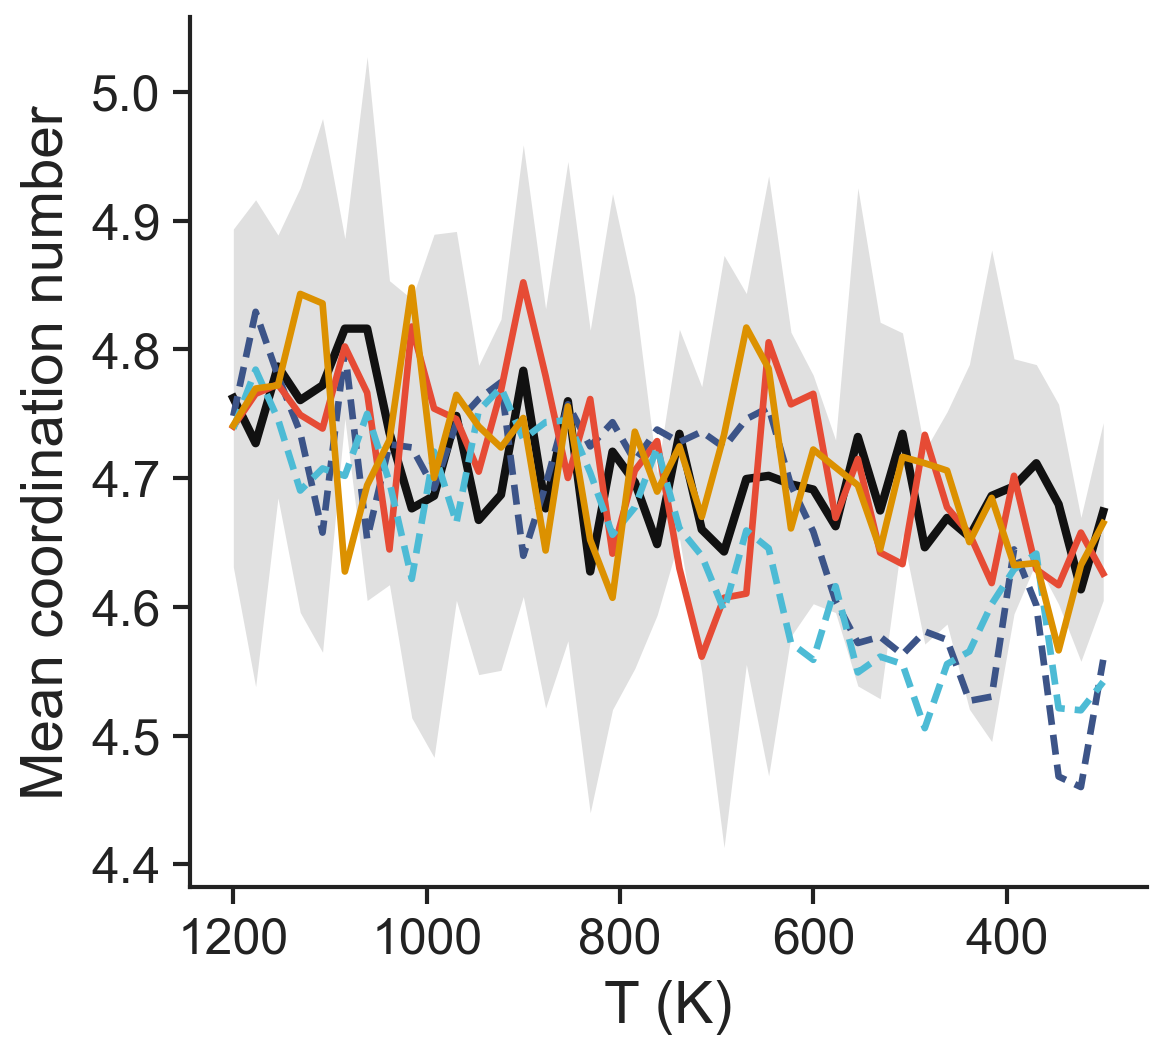

In [8]:
def draw_c(fig, spec):
    return path_panel(fig, spec, Q, "mean_cn_all", "Mean coordination number", False)
panel_run("c", draw_c)

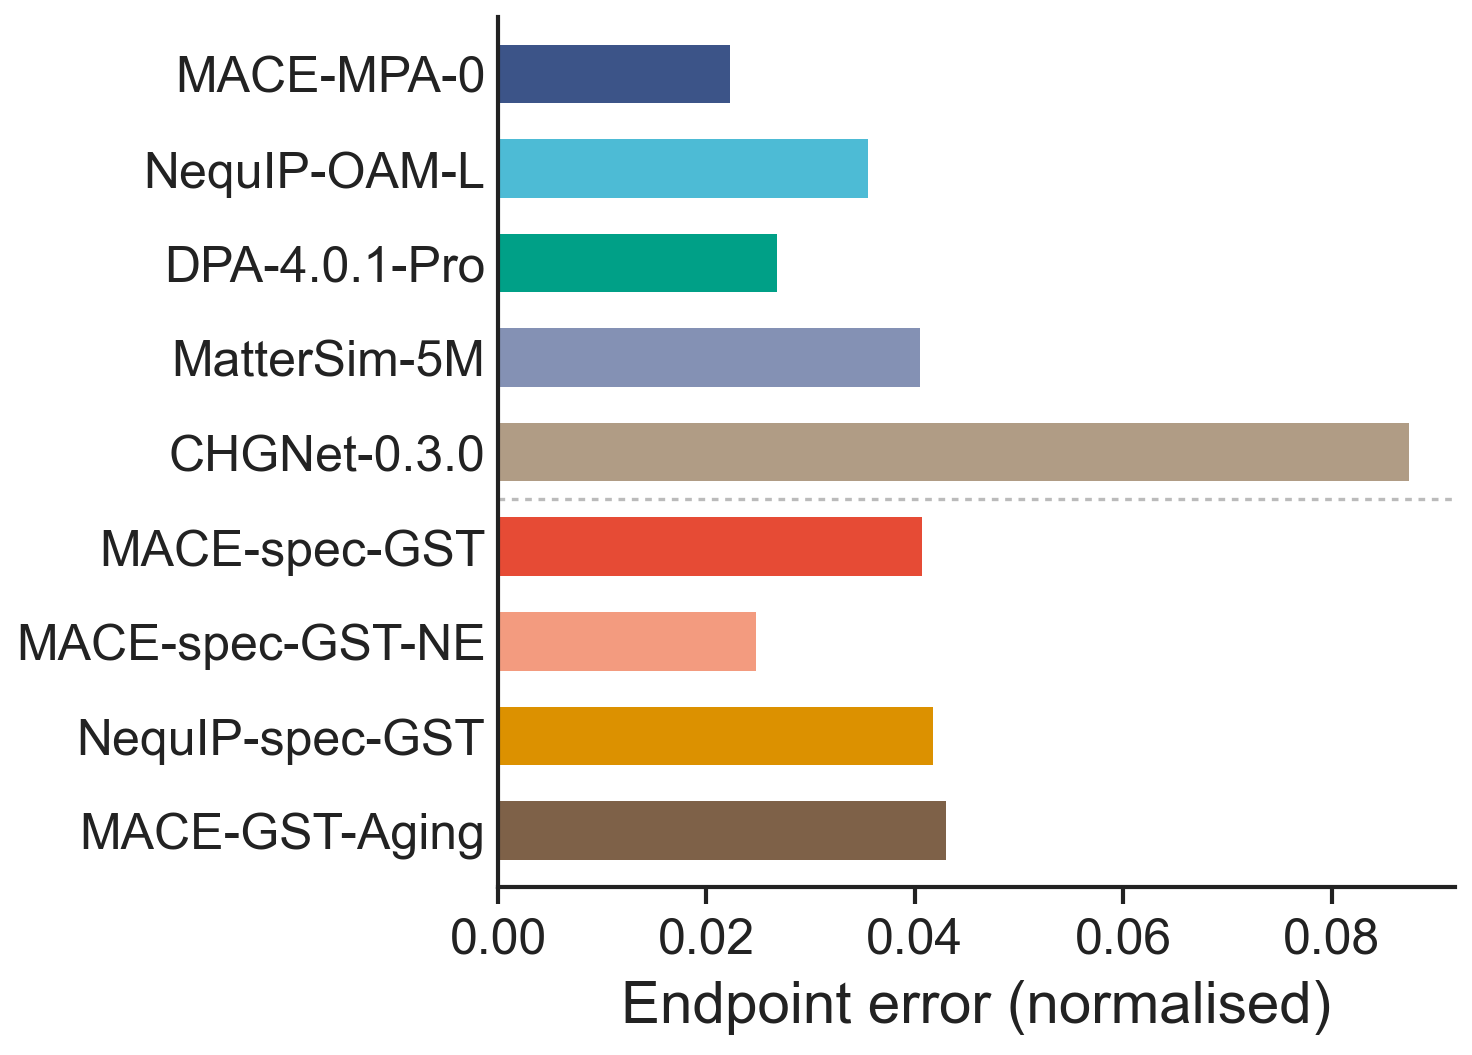

In [9]:
def raw_bars(fig, spec, key, xlabel, show_labels):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, show_labels)
    row = ROW[key]
    for k in SHOWCASE:
        v = row.raw.get(k)
        if v is None: continue
        ax.barh(y[k], v, height=0.62, color=col(k), lw=0)
    ax.set_xlabel(xlabel)
    return ax
def draw_d(fig, spec):
    return raw_bars(fig, spec, "pathway endpoint error", "Endpoint error (normalised)", True)
panel_run("d", draw_d)

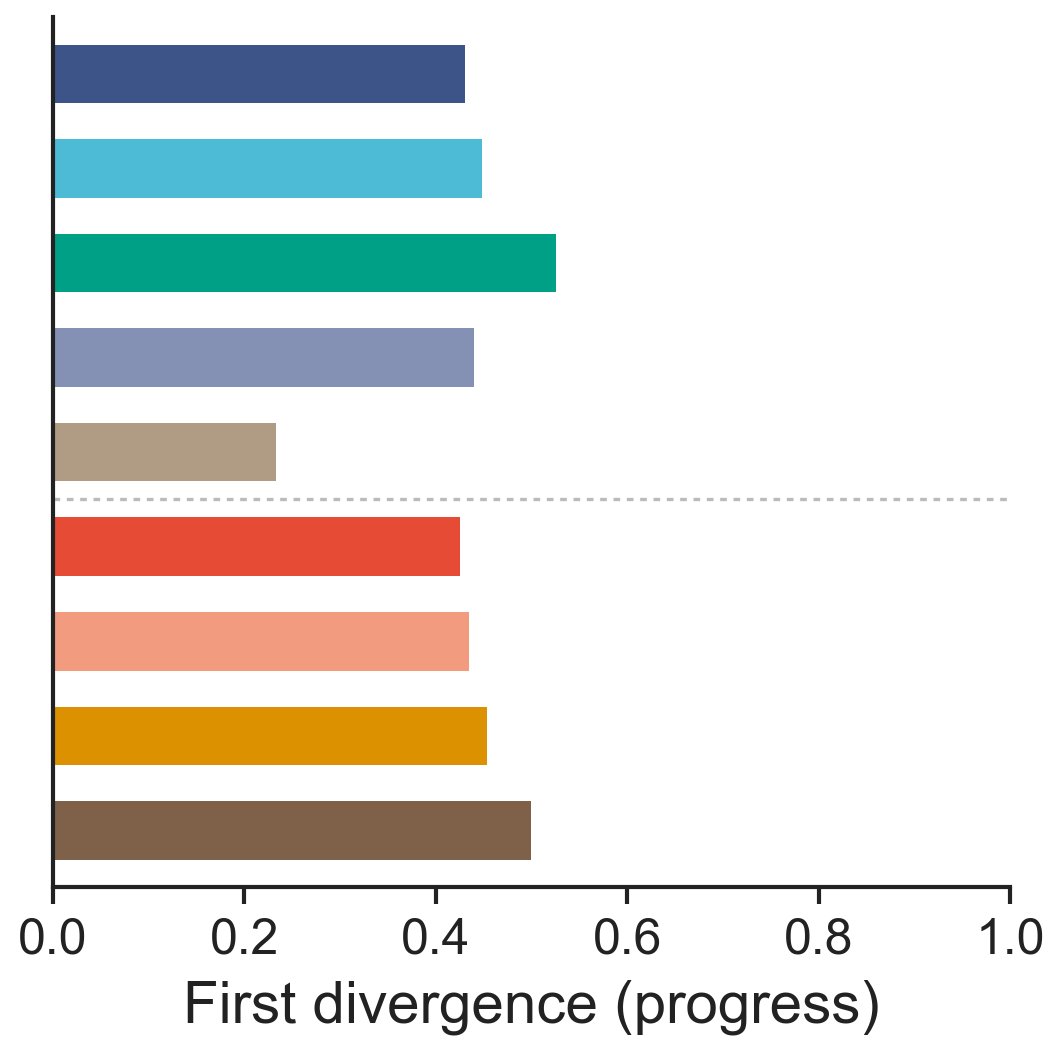

In [10]:
def draw_e(fig, spec):
    ax = raw_bars(fig, spec, "first divergence", "First divergence (progress)", False)
    ax.set_xlim(0, 1)
    return ax
panel_run("e", draw_e)

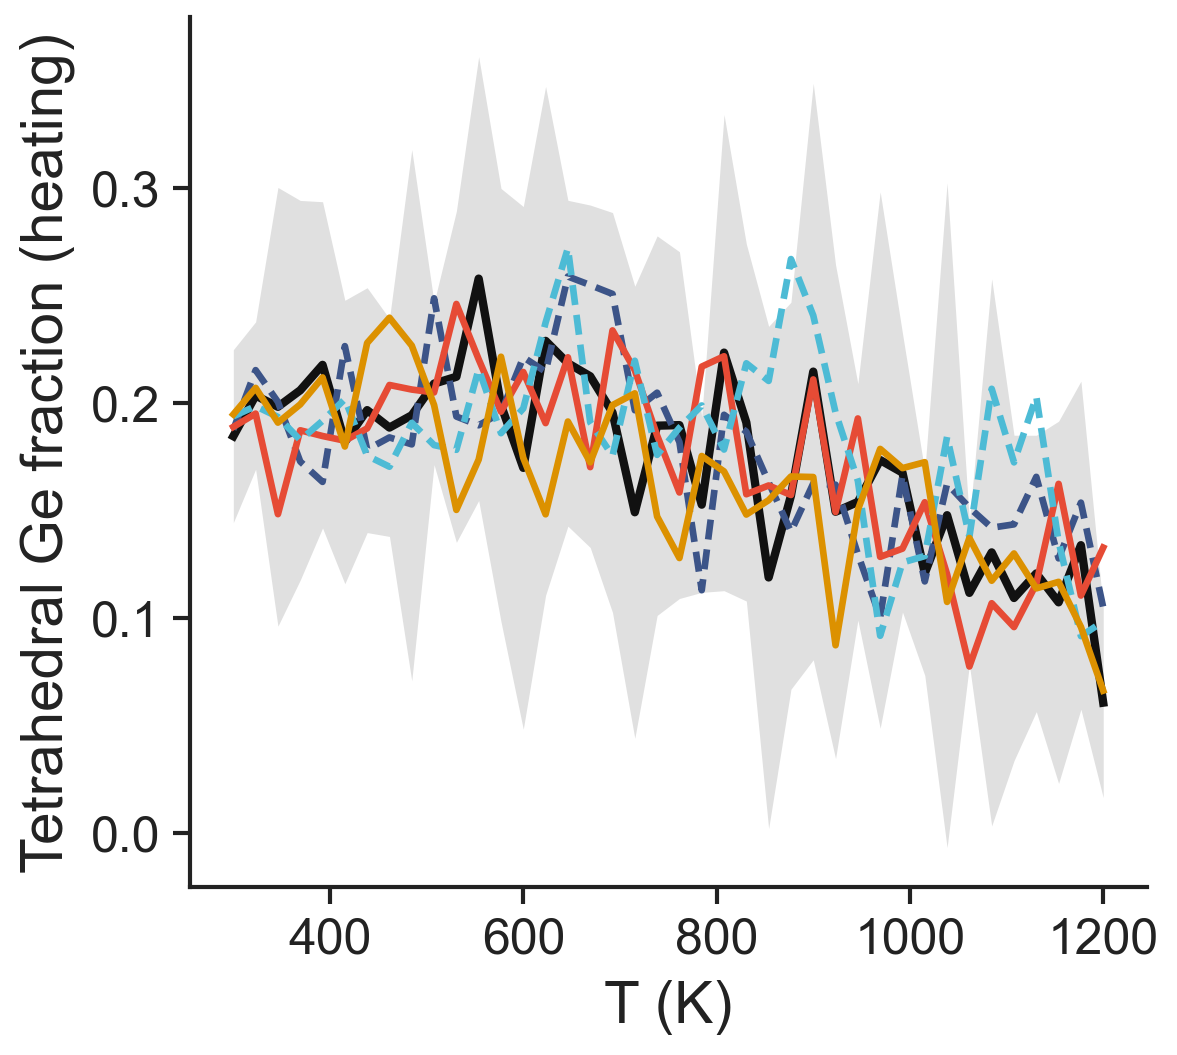

In [11]:
def draw_f(fig, spec):
    return path_panel(fig, spec, HT, "tetrahedral_fraction", "Tetrahedral Ge fraction (heating)", False, invert=False)
panel_run("f", draw_f)

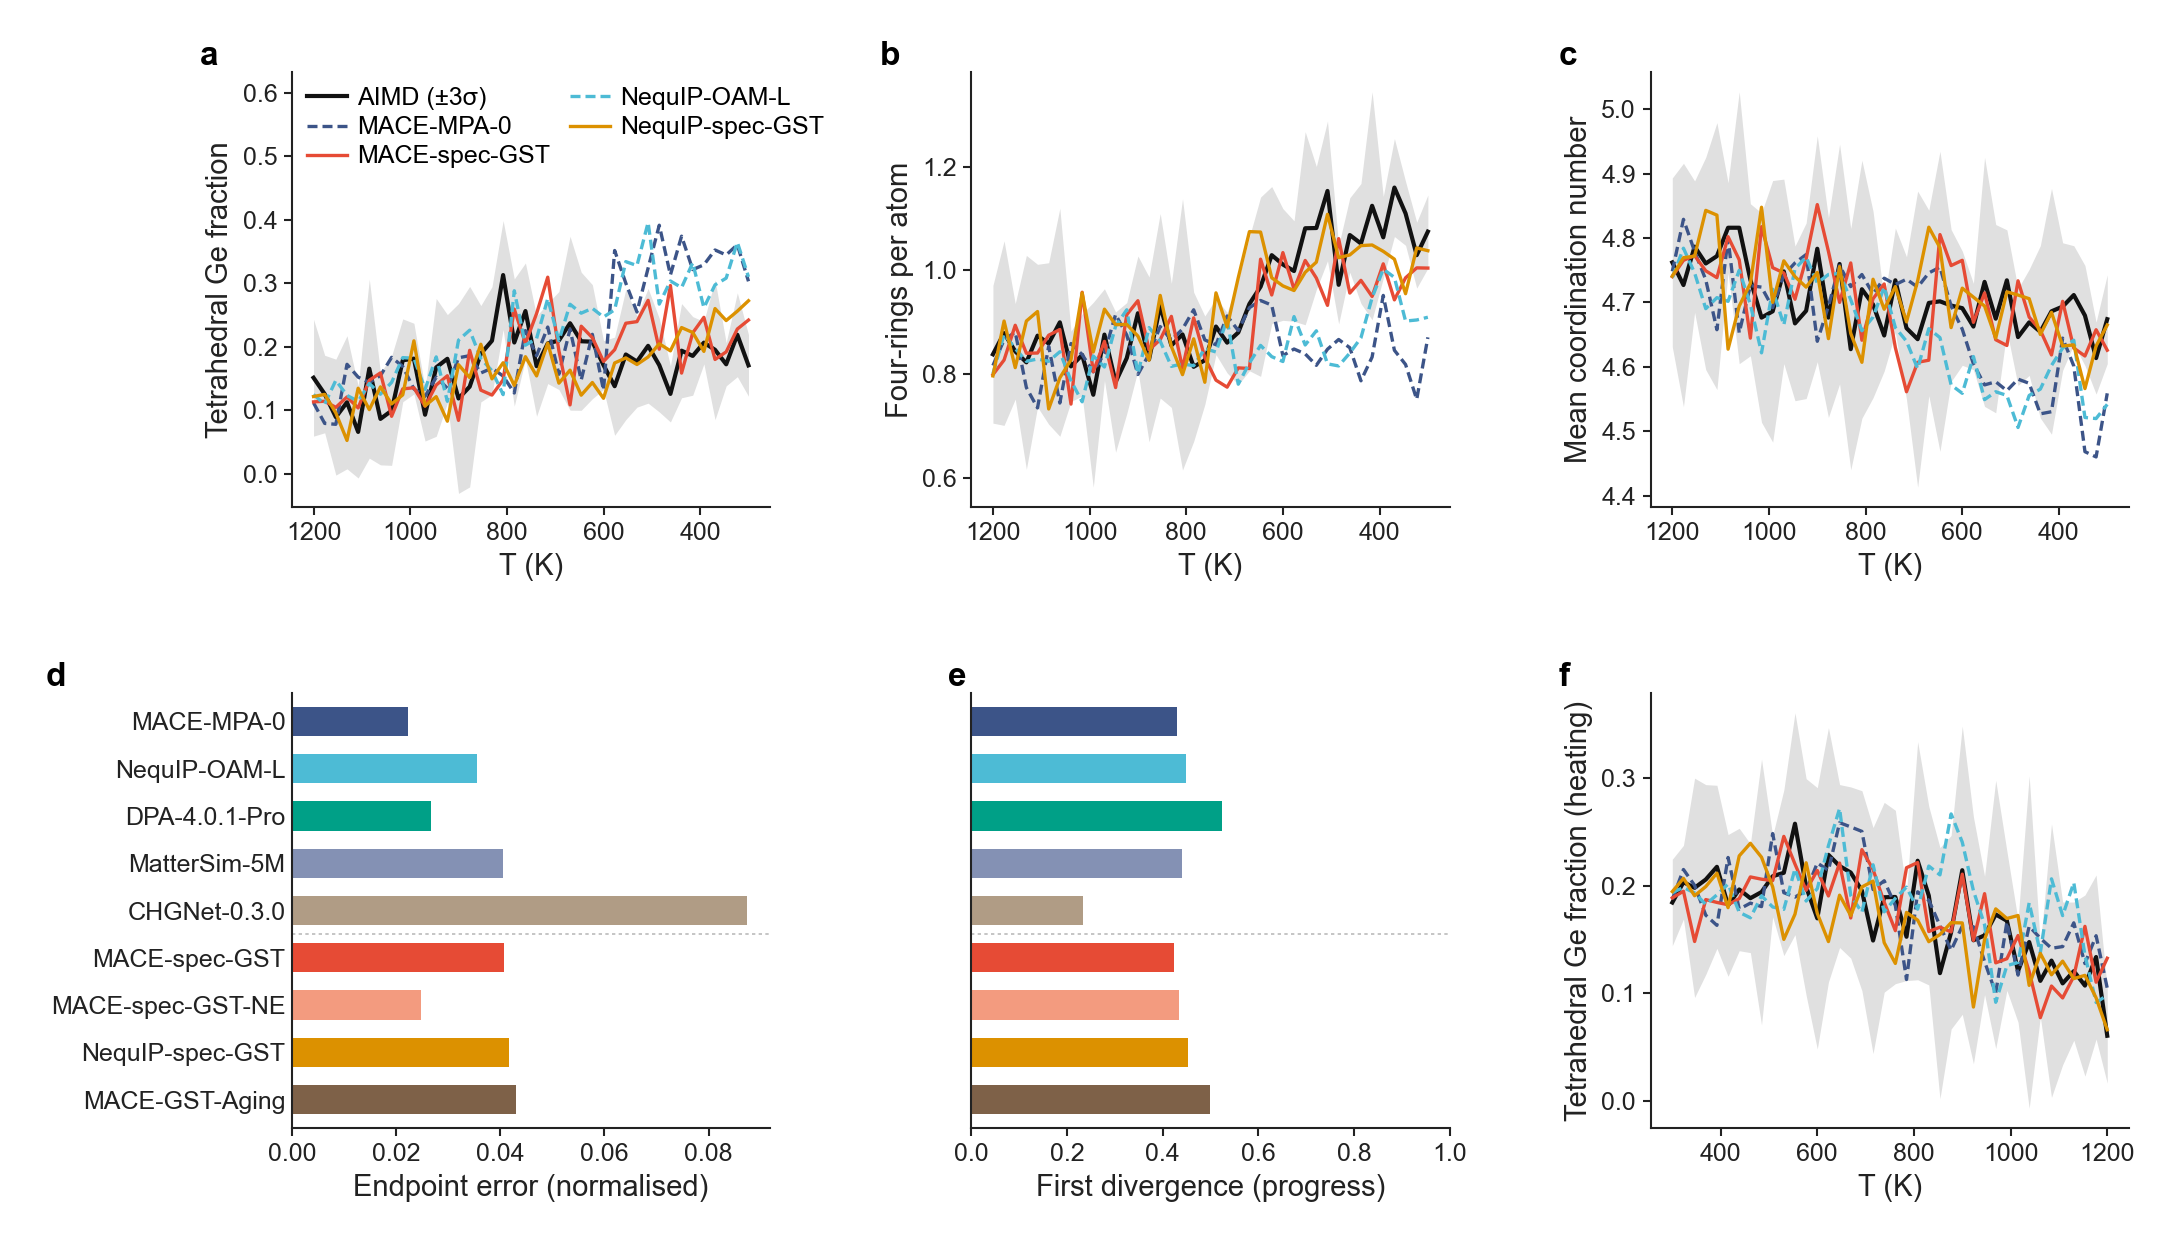

In [12]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig7_L5")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))